# Раздел 1. Основы теории вероятностей
---

## Тема 2. Частотное и классическое определение вероятности
---

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from itertools import product

### Задача
> Бросают два игральных кубика. Найти вероятность того, что сумма выпавших очков кратна $3$. Показать моделированием, что частота этого события при росте числа опытов приближается к вероятности, найденной по классическому определению.

Есть два способа ответить на вопрос «какова вероятность события $A$».

* **Классическое определение.** Если исходов конечное число и все они равновозможны, то

$P(A) = \frac{m}{n}$,

где $n$ – число всех исходов, $m$ – число исходов, благоприятствующих $A$. Вероятность находится **до** опыта, чистым подсчётом.

* **Частотное (статистическое) определение.** Опыт повторяют $N$ раз, и если событие $A$ наступило $M$ раз, то его частота

$W(A) = \frac{M}{N}$

Частота случайна: в разных сериях опытов она получается разной.

Связь между ними даёт **теорема Бернулли** (закон больших чисел, §6.4 учебника): при росте числа опытов частота события сходится по вероятности к его вероятности. Проверим это на нашей задаче.

### Классическое решение

Кубики различимы, поэтому исход – упорядоченная пара $(i, j)$, и все пары равновозможны. По правилу произведения (**размещения с повторениями**):

$n = \overline{A}_6^2 = 6^2 = 36$

Сумма кратна $3$ в случаях $3$, $6$, $9$ и $12$ очков. Число пар для каждой суммы:

$3: (1,2),(2,1) - 2$; $\quad 6: (1,5),(2,4),(3,3),(4,2),(5,1) - 5$;

$9: (3,6),(4,5),(5,4),(6,3) - 4$; $\quad 12: (6,6) - 1$.

$m = 2 + 5 + 4 + 1 = 12$

$P(A) = \frac{m}{n} = \frac{12}{36} = \frac{1}{3}$

Проверим подсчёт полным перебором всех $36$ исходов:

In [2]:
outcomes = list(product(range(1, 7), repeat=2))   # все пары (i, j) – 36 исходов
m = sum(1 for i, j in outcomes if (i + j) % 3 == 0)

print(f"благоприятствующих исходов: {m} из {len(outcomes)}")
P = m / len(outcomes)
round(P, 4)

благоприятствующих исходов: 12 из 36


0.3333

### Моделирование

Один опыт – бросок двух кубиков. Событие $A$ наступило, если сумма очков делится на $3$. Бросим кубики $100\,000$ раз и посчитаем долю успешных опытов.

In [3]:
n = 100000
rng = np.random.default_rng()

d1 = rng.integers(1, 7, n)   # первый кубик: целые числа от 1 до 6
d2 = rng.integers(1, 7, n)   # второй кубик
hit = (d1 + d2) % 3 == 0     # массив из T/F (считаем, как 1/0): сумма кратна 3

print("событие наступило:", hit.sum(), "раз из", n)
round(hit.mean(), 4)

событие наступило: 33318 раз из 100000


np.float64(0.3332)

Частота близка к $\frac{1}{3} \approx 0{,}3333$. Посмотрим, как она ведёт себя на первых $N$ опытах из этой серии:

In [4]:
for n_i in [10, 100, 1000, 10000, 100000]:
    w_i = hit[:n_i].mean()
    print(f"N = {n_i:>6}:  W = {w_i:.4f},  |W - P| = {abs(w_i - P):.4f}")

N =     10:  W = 0.5000,  |W - P| = 0.1667
N =    100:  W = 0.3300,  |W - P| = 0.0033
N =   1000:  W = 0.3370,  |W - P| = 0.0037
N =  10000:  W = 0.3354,  |W - P| = 0.0021
N = 100000:  W = 0.3332,  |W - P| = 0.0002


При малых $N$ частота может заметно отличаться от $\frac{1}{3}$, а с ростом $N$ отклонение уменьшается.

### Иллюстрация 1. Сходимость частоты

Проведём пять независимых серий по $10\,000$ бросков. После каждого броска пересчитаем частоту $W = M/N$ по всем уже проведённым опытам и нарисуем её как функцию $N$. Горизонтальная линия – классическая вероятность $\frac{1}{3}$.

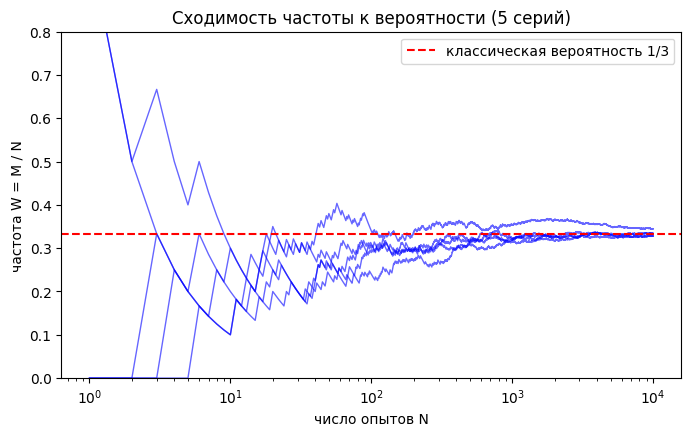

In [5]:
N = 10000
steps = np.arange(1, N + 1)    # номера опытов 1, 2, ..., N

plt.figure(figsize=(8, 4.5))
for _ in range(5):
    a = rng.integers(1, 7, N)
    b = rng.integers(1, 7, N)
    run = np.cumsum((a + b) % 3 == 0) / steps   # накопленная частота после каждого опыта
    plt.plot(steps, run, color="blue", lw=1, alpha=0.6)

plt.axhline(P, color="red", ls="--", label="классическая вероятность 1/3")
plt.xscale("log")  # логарифмический масштаб: видно и начало серии, и хвост
plt.ylim(0, 0.8)
plt.xlabel("число опытов N")
plt.ylabel("частота W = M / N")
plt.title("Сходимость частоты к вероятности (5 серий)")
plt.legend()
plt.show()

В начале серии кривые сильно разбегаются (при $N = 1$ частота равна $0$ или $1$), затем «сжимаются» к красной линии. Все пять серий разные, но сходятся к одному и тому же числу.

### Иллюстрация 2. Скорость сходимости

Для одной длинной серии ($100\,000$ опытов) нарисуем отклонение $|W - P|$ в двойном логарифмическом масштабе. Для сравнения красной линией показан разброс частоты $\sqrt{\frac{P(1-P)}{N}}$ – он убывает как $\frac{1}{\sqrt{N}}$.

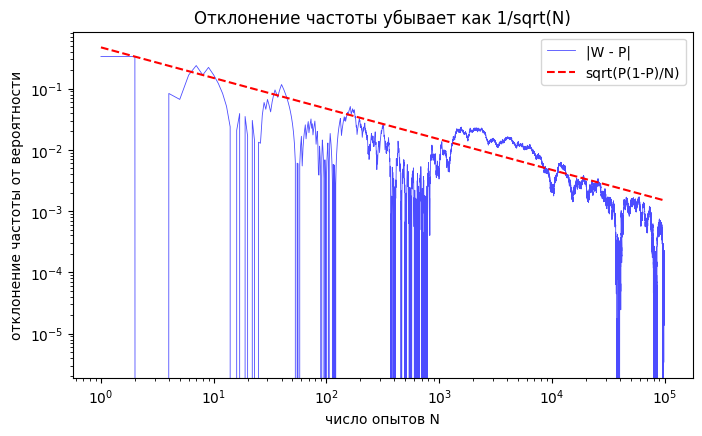

In [6]:
steps_all = np.arange(1, n + 1)
run_all = np.cumsum(hit) / steps_all       # накопленная частота для серии из n опытов
err = np.abs(run_all - P)                  # отклонение частоты от вероятности

plt.figure(figsize=(8, 4.5))
plt.loglog(steps_all, err, color="blue", lw=0.6, alpha=0.7, label="|W - P|")
plt.loglog(steps_all, np.sqrt(P * (1 - P) / steps_all), color="red", ls="--",
           label="sqrt(P(1-P)/N)")   # типичный размер отклонения
plt.xlabel("число опытов N")
plt.ylabel("отклонение частоты от вероятности")
plt.title("Отклонение частоты убывает как 1/sqrt(N)")
plt.legend()
plt.show()

Синяя «ломаная» (провалы вниз – моменты, когда частота случайно почти совпадает с $\frac{1}{3}$) идёт вдоль красной линии. Значит, отклонение убывает как $\frac{1}{\sqrt{N}}$: чтобы уменьшить ошибку в $10$ раз, нужно в $100$ раз больше опытов.

**Вывод.** Классическая вероятность $P(A) = \frac{1}{3}$ получена подсчётом без единого опыта, а частота $W(A)$ получена только из опытов, без знания формулы. При росте числа опытов они совпадают – в этом и состоит связь частотного и классического определений.

**Ответ:** $P(A) = \frac{1}{3} \approx 0{,}3333$.